In [178]:
# Peloton: Find out why subscribers of a fitness app cancel, and give leadership an evidence-backed plan to keep them.

import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

In [179]:
# Load and clean the subscriptions and usage datasets. Check for repeated records, inconsistent labels and missing values, and explain how you handled each.

In [180]:
subscriptions = pd.read_csv(r'/Users/karanthapa/Desktop/customer-churn-analysis/Peloton_churn_analysis/datasets/subscriptions.csv')
usage = pd.read_csv(r'/Users/karanthapa/Desktop/customer-churn-analysis/Peloton_churn_analysis/datasets/usage.csv')

In [181]:
# creating the copy of each dataset 
sub_df = subscriptions.copy()
use_df = usage.copy()

In [182]:
sub_df.head(10)

,customer_id,signup_date,plan_type,plan_tier,monthly_price,acquisition_channel,primary_device,age_group,churned,churn_date,cancel_reason
0,1,2024-09-11,monthly,basic,12.99,promo_offer,android,45-54,yes,2025-06-29,technical_issues
1,2,2025-08-14,annual,basic,9.74,promo_offer,web,45-54,no,NaN,NaN
2,3,2025-01-24,monthly,basic,12.99,referral,ios,55+,no,NaN,NaN
3,4,2024-08-15,monthly,basic,12.99,paid_social,ios,25-34,yes,2024-08-20,not_using_enough
4,5,2025-06-24,annual,plus,14.99,paid_social,android,55+,no,NaN,NaN
5,6,2024-08-11,monthly,plus,19.99,organic,web,55+,yes,2025-03-01,not_using_enough
6,7,2024-11-05,monthly,plus,19.99,organic,android,25-34,yes,2024-12-28,other
7,8,2025-10-20,annual,plus,14.99,organic,web,45-54,no,NaN,NaN
8,9,2024-08-29,annual,basic,9.74,promo_offer,ios,25-34,yes,2025-07-27,too_expensive
9,10,2025-01-26,annual,basic,9.74,organic,ios,35-44,no,NaN,NaN


In [183]:
use_df.head(10)

,customer_id,month,workouts_completed,minutes_active,classes_booked,support_tickets
0,1,2024-09,5,140.0,0,0
1,1,2024-10,4,116.0,0,0
2,1,2024-11,7,208.0,0,0
3,1,2024-12,5,109.0,0,0
4,1,2025-01,1,41.0,0,0
5,1,2025-02,6,119.0,0,0
6,1,2025-03,5,167.0,0,3
7,1,2025-04,3,78.0,0,2
8,1,2025-05,7,245.0,0,0
9,1,2025-06,3,111.0,0,1


In [184]:
sub_df.shape, use_df.shape

((4200, 11), (30685, 6))

# Checking the null values 

In [185]:
sub_df.isnull().sum()

customer_id               0
signup_date               0
plan_type                 0
plan_tier                 0
monthly_price             0
acquisition_channel       0
primary_device            0
age_group                 0
churned                   0
churn_date             2432
cancel_reason          2814
dtype: int64

In [186]:
use_df.isnull().sum()

customer_id             0
month                   0
workouts_completed      0
minutes_active        506
classes_booked          0
support_tickets         0
dtype: int64

In [187]:
sub_df['cancel_reason'] = sub_df['cancel_reason'].where(
    sub_df['churned'] == 'no', sub_df['cancel_reason'].fillna('unknown')
).fillna('not_churned')

In [188]:
use_df['minutes_missing'] = use_df['minutes_active'].isna().astype(int)
use_df['minutes_active'] = use_df['minutes_active'].fillna(use_df['workouts_completed'] * 30)


# checking the duplicates 

In [189]:
sub_df.duplicated().sum()

np.int64(0)

In [190]:
use_df.duplicated().sum()

np.int64(160)

# deleting the duplicates 

In [191]:
sub_df.drop_duplicates(inplace=True)
use_df.drop_duplicates(inplace=True)

In [192]:
use_df.duplicated().sum()

np.int64(0)

In [193]:
sub_df.duplicated().sum()

np.int64(0)

# checking the datatype of sub_df

In [194]:
sub_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          4200 non-null   int64  
 1   signup_date          4200 non-null   object 
 2   plan_type            4200 non-null   object 
 3   plan_tier            4200 non-null   object 
 4   monthly_price        4200 non-null   float64
 5   acquisition_channel  4200 non-null   object 
 6   primary_device       4200 non-null   object 
 7   age_group            4200 non-null   object 
 8   churned              4200 non-null   object 
 9   churn_date           1768 non-null   object 
 10  cancel_reason        4200 non-null   object 
dtypes: float64(1), int64(1), object(9)
memory usage: 361.1+ KB


# changing signup_date and churn_date from object Dtype to datetime Dtype

In [195]:
sub_df['signup_date'] = pd.to_datetime(sub_df['signup_date'])

sub_df['churn_date'] = pd.to_datetime(sub_df['churn_date'])

# changing age_group from oject Dtype to Categorical Dtype

In [196]:
order = ['18-24', '25-34', '35-44', '45-54', '55+']
sub_df['age_group'] = pd.Categorical(sub_df['age_group'], categories=order, ordered=True)

# checking the Dtype for use_df

In [197]:
use_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 30525 entries, 0 to 30684
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         30525 non-null  int64  
 1   month               30525 non-null  object 
 2   workouts_completed  30525 non-null  int64  
 3   minutes_active      30525 non-null  float64
 4   classes_booked      30525 non-null  int64  
 5   support_tickets     30525 non-null  int64  
 6   minutes_missing     30525 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 1.9+ MB


# changing month from Object Dtype to Datetime Dtyep

In [198]:
use_df['month'] = pd.to_datetime(use_df['month'], format='%Y-%m')

# making all the values of plan_tier to lower case

In [199]:
sub_df['plan_tier'] = sub_df['plan_tier'].str.lower()

# Explore churn rates across plan type, plan tier, acquisition channel, device and age group, and across tenure.

## Hint : Members who joined recently haven't had much time to cancel, so their overall churn looks low. A monthly churn rate compares groups fairly: cancellations in a month divided by the members who were active that month

In [200]:
months = pd.period_range(sub_df['signup_date'].min(), sub_df['churn_date'].max(), freq='M')

parts = []
for m in months:
    active = sub_df[(sub_df['signup_date'] <= m.end_time) &
                    (sub_df['churn_date'].isna() | (sub_df['churn_date'] >= m.start_time))].copy()
    active['month'] = m
    active['cancelled'] = active['churn_date'].between(m.start_time, m.end_time).astype(int)
    parts.append(active)

df = pd.concat(parts, ignore_index=True)

Customer Who Churned 

In [201]:
df[df['cancelled'] == 1]

,customer_id,signup_date,plan_type,plan_tier,monthly_price,acquisition_channel,primary_device,age_group,churned,churn_date,cancel_reason,month,cancelled
50,1363,2024-07-04,monthly,basic,12.99,partner,android,25-34,yes,2024-07-21,found_alternative,2024-07,1
55,1563,2024-07-12,monthly,basic,12.99,promo_offer,android,45-54,yes,2024-07-22,too_expensive,2024-07,1
65,1686,2024-07-02,monthly,premium,29.99,promo_offer,android,25-34,yes,2024-07-02,not_using_enough,2024-07,1
91,2399,2024-07-19,monthly,plus,19.99,promo_offer,ios,18-24,yes,2024-07-26,found_alternative,2024-07,1
99,2546,2024-07-12,monthly,premium,29.99,promo_offer,ios,55+,yes,2024-07-31,too_expensive,2024-07,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
31739,4109,2025-01-21,annual,plus,14.99,partner,android,35-44,yes,2025-12-01,unknown,2025-12,1
31747,4123,2024-08-31,monthly,basic,12.99,organic,web,35-44,yes,2025-12-28,unknown,2025-12,1
31750,4128,2025-07-18,monthly,basic,12.99,referral,android,25-34,yes,2025-12-01,not_using_enough,2025-12,1
31757,4144,2024-07-06,monthly,basic,12.99,referral,ios,18-24,yes,2025-12-13,other,2025-12,1


# Churn rate by group 

In [202]:
plan_type_churn = (df.groupby('plan_type')['cancelled'].mean() * 100).round(1)
plan_type_churn

plan_type
annual     3.0
monthly    7.5
Name: cancelled, dtype: float64

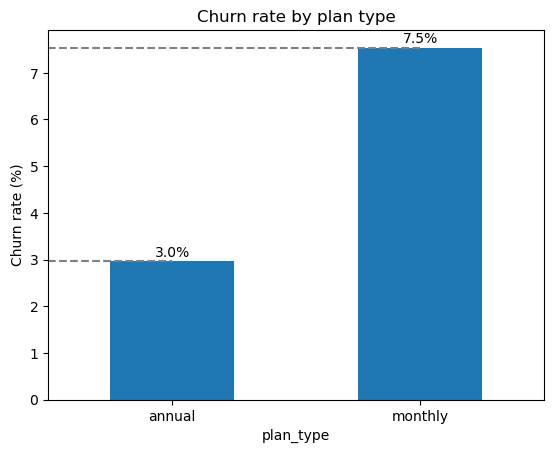

In [203]:
plan_type_churn = df.groupby('plan_type')['cancelled'].mean() * 100
overall = df['cancelled'].mean() * 100
for i, v in enumerate(plan_type_churn):
    plt.hlines(v, xmin=-0.5, xmax=i, colors='grey', linestyles='--')
    plt.text(i, v + 0.1, f'{v:.1f}%', ha='center')

plan_type_churn.plot(kind='bar')
plt.title('Churn rate by plan type')
plt.ylabel('Churn rate (%)')
plt.xticks(rotation=0)
plt.show()

Monthly subscribers churn at 7.5%, compared with 3.0% for annual subscribers. That makes monthly churn 2.5 times higher. Annual plans lock in a longer commitment, while monthly users can cancel at any time with no penalty. Offering monthly users an incentive to switch to annual (a discount or a free month, for example) could be one of the most effective retention levers.

In [204]:
plan_tier_churn = (df.groupby('plan_tier')['cancelled'].mean() * 100).round(1)
plan_tier_churn

plan_tier
basic      5.6
plus       5.5
premium    5.7
Name: cancelled, dtype: float64

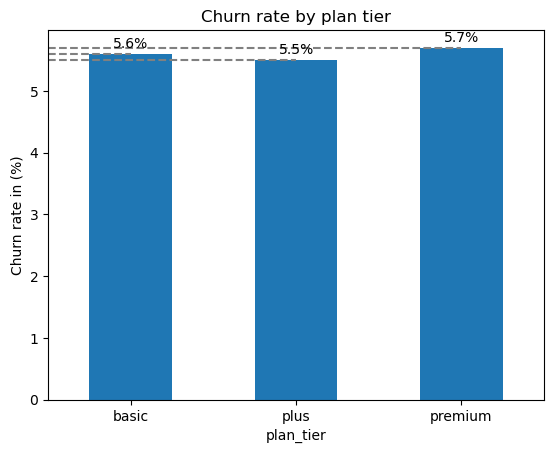

In [205]:
plan_tier_churn = (df.groupby('plan_tier')['cancelled'].mean() * 100).round(1)

plan_tier_churn.plot(kind='bar')
for i, v in enumerate(plan_tier_churn):
    plt.hlines(v, xmin=-0.5, xmax=i, colors='grey', linestyles='--')
    plt.text(i, v + 0.1, f'{v:.1f}%', ha='center')
plt.title('Churn rate by plan tier')
plt.ylabel('Churn rate in (%)')
plt.xticks(rotation=0)
plt.show()

Churn barely changes across tiers: basic 5.6%, plus 5.5%, premium 5.7%. The 0.2 percentage point gap is too small to matter in practice and is most likely noise. Plan tier is not a meaningful churn driver, so paying more or less for features doesn’t change whether users stay.

In [206]:
acquisition_channel_churn = (df.groupby('acquisition_channel')['cancelled'].mean() * 100).round(1)
acquisition_channel_churn

acquisition_channel
organic        5.2
paid_social    5.2
partner        5.8
promo_offer    7.3
referral       4.1
Name: cancelled, dtype: float64

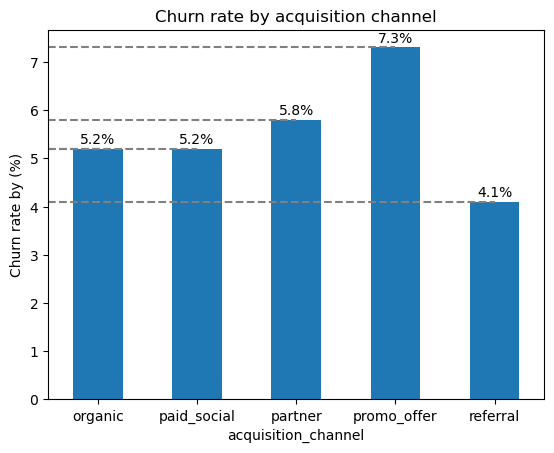

In [207]:
acquisition_channel_churn.plot(kind='bar')
for i, v in enumerate(acquisition_channel_churn):
    plt.hlines(v, xmin=-0.5, xmax=i, colors='grey', linestyles='--')
    plt.text(i, v + 0.1, f'{v:.1f}%', ha='center')

plt.title('Churn rate by acquisition channel')
plt.ylabel('Churn rate by (%)')
plt.xticks(rotation=0)
plt.show()

Users acquired through promo offers churn the most at 7.3%, and referral users churn the least at 4.1%. Organic and paid social are both at 5.2%, and partner is at 5.8%. Promo users are about 1.8 times more likely to churn than referred users. They were probably attracted by the discount and leave once it ends. Referred users likely have friends on the platform, which keeps them engaged. Investing in the referral program and reviewing promo offer terms could improve retention.

# Churn by tenure

In [208]:
df['tenure_month'] = (df['month'] - df['signup_date'].dt.to_period('M')).apply(lambda x: x.n) + 1

In [209]:
tenure = df.groupby('tenure_month')['cancelled'].mean() * 100

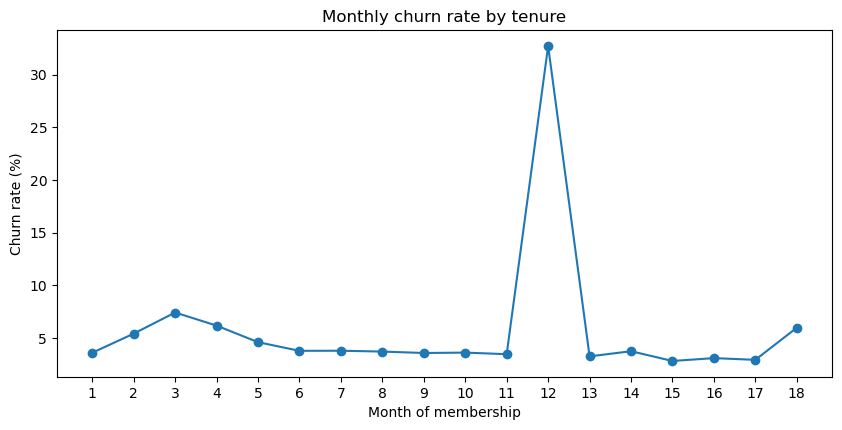

In [210]:
tenure.plot(marker='o', figsize=(10, 4.5))
plt.title('Monthly churn rate by tenure')
plt.xlabel('Month of membership')
plt.ylabel('Churn rate (%)')
plt.xticks(range(1, 19))
plt.show()

There are three clear patterns:

1. Early churn (months 2 to 4): churn rises to a peak of about 7.4% in month 3. Users who don’t build a habit early tend to leave. This could also line up with introductory offers expiring.
2. Stable period (months 5 to 11): churn settles at around 3.5% to 4%.
3. Month 12 spike: churn jumps to about 33%, by far the highest point in the data. This almost certainly reflects annual plan renewals, where users decide whether to recommit. Churn drops to around 3% straight after, so users who renew are very loyal.

Month 18 rises again to about 6%. Check how many users reach month 18, because a small sample there could make the number unreliable.

Recommendation: run renewal campaigns in months 10 to 11 and strengthen onboarding during the first 3 months.

/var/folders/z3/0l9hbnmx27qg6j4p8vp3gzzr0000gn/T/ipykernel_19566/2485385843.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_churn = df.groupby('age_group')['cancelled'].mean() * 100


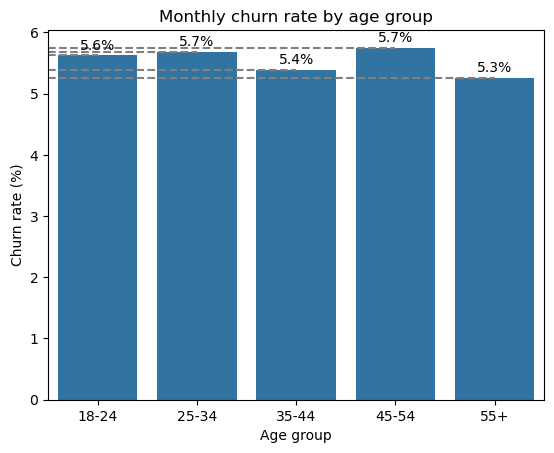

In [211]:
order = ['18-24', '25-34', '35-44', '45-54', '55+']

age_churn = df.groupby('age_group')['cancelled'].mean() * 100
for i, v in enumerate(age_churn):
    plt.hlines(v, xmin=-0.5, xmax=i, colors='grey', linestyles='--')
    plt.text(i, v + 0.1, f'{v:.1f}%', ha='center')

sns.barplot(x=age_churn.index, y=age_churn.values, order=order)
plt.title('Monthly churn rate by age group')
plt.xlabel('Age group')
plt.ylabel('Churn rate (%)')
plt.show()

Churn is roughly flat across age groups, between about 5.3% and 5.8%. The 45 to 54 group is slightly higher and the 55+ group slightly lower, but the gap is small. Age is not a meaningful churn driver.

In [212]:
devices = df.groupby('primary_device')['cancelled'].mean() * 100
devices

primary_device
android    6.033587
ios        5.323473
web        5.202754
Name: cancelled, dtype: float64

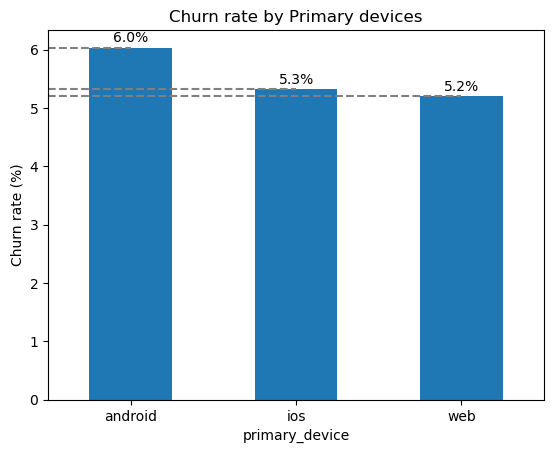

In [213]:
devices.plot(kind='bar')
for i, v in enumerate(devices):
    plt.hlines(v, xmin=-0.5, xmax=i, colors='grey', linestyles='--')
    plt.text(i, v + 0.1, f'{v:.1f}%', ha='center')

plt.title('Churn rate by Primary devices')
plt.ylabel('Churn rate (%)')
plt.xticks(rotation=0)
plt.show()

Android users churn the most at 6.0%, followed by iOS at 5.3% and web at 5.2%. The gap is small, but Android stands out. It could point to app performance or user experience problems on Android, which is worth investigating.

### Overall summary

The strongest churn drivers are plan type, tenure (especially the 12 month renewal point) and acquisition channel. Plan tier and age group have very little effect, and device type has a small effect. To make sure the small differences (tier, age, device) aren’t just noise, you could run a chi-square test.

# Combine the usage data with subscriptions to see how engagement and support contact relate to churn, including how customers behave in their first month.


In [214]:
use_df['month'] = use_df['month'].dt.to_period('M')

In [215]:
df_combined = pd.merge(df, use_df, on=['customer_id', 'month'], how='left')
df_combined.head()

,customer_id,signup_date,plan_type,plan_tier,monthly_price,acquisition_channel,primary_device,age_group,churned,churn_date,cancel_reason,month,cancelled,tenure_month,workouts_completed,minutes_active,classes_booked,support_tickets,minutes_missing
0,42,2024-07-13,annual,basic,9.74,promo_offer,web,45-54,yes,2025-06-12,unknown,2024-07,0,1,7.0,166.0,0.0,0.0,0.0
1,146,2024-07-03,monthly,basic,12.99,paid_social,ios,25-34,no,NaT,not_churned,2024-07,0,1,7.0,169.0,0.0,0.0,0.0
2,204,2024-07-11,monthly,basic,12.99,promo_offer,android,25-34,yes,2024-09-20,not_using_enough,2024-07,0,1,1.0,19.0,0.0,0.0,0.0
3,222,2024-07-06,monthly,basic,12.99,organic,web,25-34,yes,2024-09-22,other,2024-07,0,1,7.0,137.0,0.0,0.0,0.0
4,249,2024-07-08,monthly,plus,19.99,referral,android,25-34,no,NaT,not_churned,2024-07,0,1,14.0,538.0,4.0,0.0,0.0


In [216]:
df_combined['workout_level'] = pd.cut(df_combined['workouts_completed'], bins=[-1, 0, 2, 5, 100], labels=['0', '1-2', '3-5', '6+'])


In [217]:
workout_churn = (df_combined.groupby('workout_level', observed=True)['cancelled'].mean() * 100).round(1)
workout_churn

workout_level
0      13.8
1-2     8.2
3-5     3.8
6+      2.8
Name: cancelled, dtype: float64

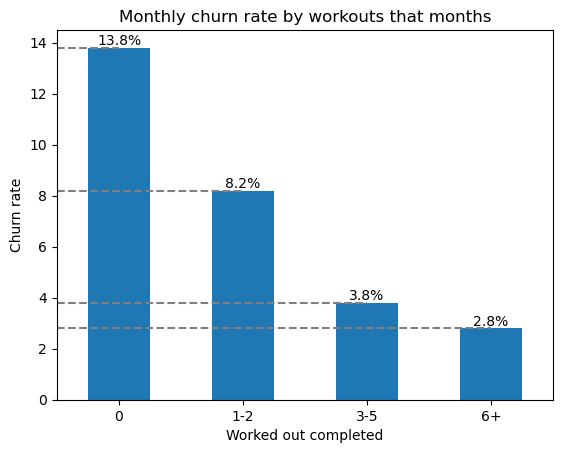

In [218]:
workout_churn.plot(kind='bar')
for i, v in enumerate(workout_churn):
    plt.hlines(v, xmin=-0.5, xmax=i, colors='grey', linestyles='--')
    plt.text(i, v + 0.1, f'{v:.1f}%', ha='center')

plt.title('Monthly churn rate by workouts that months')
plt.xlabel('Worked out completed')
plt.ylabel('Churn rate')
plt.xticks(rotation=0)
plt.show()

Engagement: Members who completed no workouts in a month churned at 13.8% that month, against 2.8% for those with 6 or more. Low activity is a strong warning sign, which matches the top cancel reason, “not using enough”.

In [219]:
df_combined['support_tickets'].unique()

array([ 0.,  1.,  2., nan,  3.,  4.])

In [220]:
df_combined['had_ticket'] = (df_combined['support_tickets']  > 0).map({True: 'yes', False:'no'})

In [221]:
ticket_churn = (df_combined[df_combined['support_tickets'].notna()].groupby('had_ticket')['cancelled'].mean() * 100).round(1)
ticket_churn

had_ticket
no      5.0
yes    11.7
Name: cancelled, dtype: float64

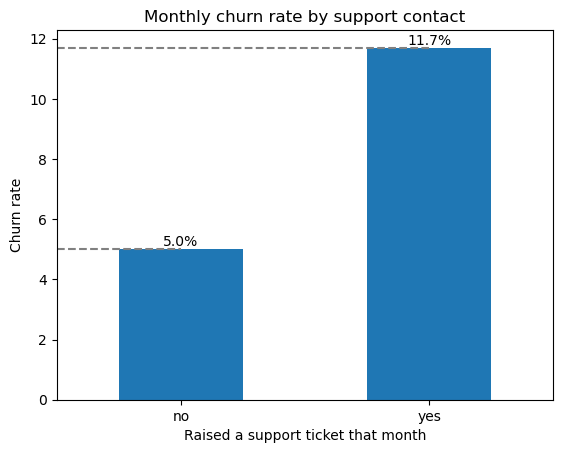

In [222]:
ticket_churn.plot(kind='bar')
for i, v in enumerate(ticket_churn):
    plt.hlines(v, xmin=-0.5, xmax=i, colors='grey', linestyles='--')
    plt.text(i, v + 0.1, f'{v:.1f}%', ha='center')

plt.title('Monthly churn rate by support contact')
plt.xlabel('Raised a support ticket that month')
plt.ylabel('Churn rate')
plt.xticks(rotation=0)
plt.show()

Support contact: Members who raised a support ticket churned at 11.7% that month, against 5.0% for those who didn’t, more than twice as likely.

In [223]:
df_combined[df_combined['tenure_month'] == 1]

,customer_id,signup_date,plan_type,plan_tier,monthly_price,acquisition_channel,primary_device,age_group,churned,churn_date,...,month,cancelled,tenure_month,workouts_completed,minutes_active,classes_booked,support_tickets,minutes_missing,workout_level,had_ticket
0,42,2024-07-13,annual,basic,9.74,promo_offer,web,45-54,yes,2025-06-12,...,2024-07,0,1,7.0,166.0,0.0,0.0,0.0,6+,no
1,146,2024-07-03,monthly,basic,12.99,paid_social,ios,25-34,no,NaT,...,2024-07,0,1,7.0,169.0,0.0,0.0,0.0,6+,no
2,204,2024-07-11,monthly,basic,12.99,promo_offer,android,25-34,yes,2024-09-20,...,2024-07,0,1,1.0,19.0,0.0,0.0,0.0,1-2,no
3,222,2024-07-06,monthly,basic,12.99,organic,web,25-34,yes,2024-09-22,...,2024-07,0,1,7.0,137.0,0.0,0.0,0.0,6+,no
4,249,2024-07-08,monthly,plus,19.99,referral,android,25-34,no,NaT,...,2024-07,0,1,14.0,538.0,4.0,0.0,0.0,6+,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26352,4110,2025-10-29,monthly,basic,12.99,paid_social,ios,25-34,no,NaT,...,2025-10,0,1,1.0,31.0,0.0,0.0,0.0,1-2,no
26357,4118,2025-10-05,monthly,basic,12.99,paid_social,ios,55+,no,NaT,...,2025-10,0,1,7.0,135.0,0.0,0.0,0.0,6+,no
26375,4146,2025-10-03,annual,basic,9.74,promo_offer,android,55+,no,NaT,...,2025-10,0,1,3.0,90.0,0.0,0.0,1.0,3-5,no
26395,4178,2025-10-29,monthly,basic,12.99,paid_social,android,35-44,no,NaT,...,2025-10,0,1,0.0,0.0,0.0,0.0,0.0,0,no


In [227]:
first_month = df_combined[(df_combined['tenure_month'] == 1) & (df_combined['workouts_completed'].notna())]
first_month.groupby('churned')[['workouts_completed', 'minutes_active','classes_booked', 'support_tickets']].mean().round(2)

,workouts_completed,minutes_active,classes_booked,support_tickets
churned,,,,
no,4.67,139.43,0.74,0.09
yes,3.03,90.66,0.51,0.10


In [228]:
first_month['workout_level'] = pd.cut(first_month['workouts_completed'],
                                      bins=[-1, 0, 2, 5, 100],
                                      labels=['0', '1-2', '3-5', '6+'])

first_month_churn = (first_month.groupby('workout_level', observed=True)['churned']
                     .apply(lambda x: (x == 'yes').mean()) * 100).round(1)
first_month_churn

/var/folders/z3/0l9hbnmx27qg6j4p8vp3gzzr0000gn/T/ipykernel_19566/2137451358.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  first_month['workout_level'] = pd.cut(first_month['workouts_completed'],


workout_level
0      58.9
1-2    51.2
3-5    41.0
6+     25.3
Name: churned, dtype: float64

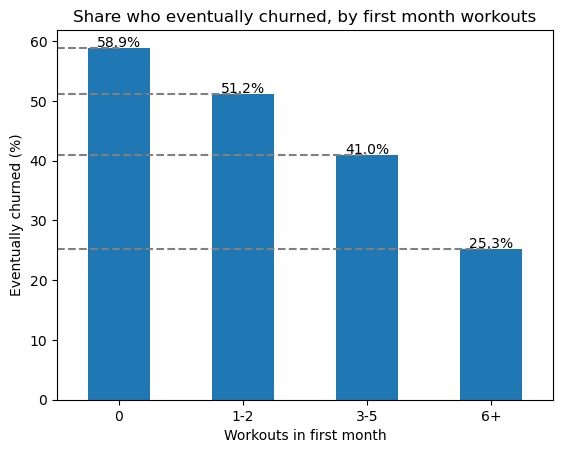

In [232]:
first_month_churn.plot(kind='bar')
for i, v in enumerate(first_month_churn):
    plt.hlines(v, xmin=-0.5, xmax=i, colors='grey', linestyles='--')
    plt.text(i, v + 0.1, f'{v:.1f}%', ha='center')
plt.title('Share who eventually churned, by first month workouts')
plt.xlabel('Workouts in first month')
plt.ylabel('Eventually churned (%)')
plt.xticks(rotation=0)
plt.show()

First month: Churners averaged 3.0 workouts in their first month, against 4.7 for members who stayed. Customers with no workouts in their first month eventually churned 59% of the time, against 25% for those with 6 or more. Early engagement strongly predicts long-term retention.

In [230]:
df_combined['tenure_band'] = pd.cut(df_combined['tenure_month'],
                                 bins=[0, 3, 6, 11, 12, 18],
                                 labels=['1-3', '4-6', '7-11', '12', '13-18'])

def check(factor):
    print('Overall:')
    print((df_combined.groupby(factor, observed=True)['cancelled'].mean() * 100).round(1))
    print('\nWithin each tenure band:')
    print((df_combined.pivot_table(index='tenure_band', columns=factor, values='cancelled',
                                aggfunc='mean', observed=True) * 100).round(1))

check('workout_level')

Overall:
workout_level
0      13.8
1-2     8.2
3-5     3.8
6+      2.8
Name: cancelled, dtype: float64

Within each tenure band:
workout_level     0   1-2   3-5    6+
tenure_band                          
1-3            14.3   8.1   3.6   2.5
4-6            10.2   8.0   3.7   2.6
7-11            8.3   4.9   2.6   2.1
12             65.4  47.2  23.1  14.7
13-18           6.7   5.0   2.9   2.7


In [231]:
for plan in ['monthly', 'annual']:
    rates = df_combined[df_combined['plan_type'] == plan].groupby('tenure_month')['cancelled'].mean()
    retained = (1 - rates.loc[1:12]).prod() * 100
    print(plan, round(retained, 1))

monthly 40.9
annual 41.0


Top 3 factors, after accounting for tenure:

1) Low engagement: members with no workouts in a month churn at 3 to 5 times the rate of active members, in every tenure band.
2) Support contact: members who raise a ticket churn about twice as often, at every stage of membership.
3) Promo acquisition: promo members churn most in their first 6 months and at renewal; referral members are the most loyal.

Plan type looked like the biggest factor but does not hold. Annual members rarely cancel mid-year, but 55% leave at renewal, so both plans retain about 41% of members after 12 months. Plan type affects when members leave, not whether they leave.

In [233]:
churned_usage = df_combined[df_combined['churned'] == 'yes'].copy()
churned_usage['churn_month'] = churned_usage['churn_date'].dt.to_period('M')
churned_usage['months_before'] = (churned_usage['churn_month'] - churned_usage['month']).apply(lambda x: x.n)

last3 = churned_usage[churned_usage['months_before'].between(0, 2)]

behaviour = last3.groupby('cancel_reason').agg(
    avg_workouts=('workouts_completed', 'mean'),
    pct_with_ticket=('support_tickets', lambda x: (x > 0).mean() * 100)
).round(2)

profile = sub_df[sub_df['churned'] == 'yes'].groupby('cancel_reason').agg(
    customers=('customer_id', 'count'),
    avg_price=('monthly_price', 'mean'),
    pct_premium=('plan_tier', lambda x: (x == 'premium').mean() * 100),
    pct_android=('primary_device', lambda x: (x == 'android').mean() * 100),
    pct_promo=('acquisition_channel', lambda x: (x == 'promo_offer').mean() * 100)
).round(1)

profile.join(behaviour)

,customers,avg_price,pct_premium,pct_android,pct_promo,avg_workouts,pct_with_ticket
cancel_reason,,,,,,,
found_alternative,175,17.5,17.7,39.4,14.9,3.37,11.83
not_using_enough,570,17.7,19.1,35.8,25.3,1.95,12.68
other,162,17.5,16.7,38.3,13.6,3.71,13.59
technical_issues,157,16.6,14.0,49.0,28.0,3.01,45.47
too_expensive,322,17.3,16.1,37.3,42.5,3.57,12.18
unknown,382,17.5,19.1,43.2,28.5,2.59,13.19


In [234]:
churner_activity = last3.groupby(['customer_id', 'cancel_reason'])['workouts_completed'].mean().reset_index()
churner_activity['low_use'] = churner_activity['workouts_completed'] < 2
(churner_activity.groupby('cancel_reason')['low_use'].mean() * 100).round(1)

cancel_reason
found_alternative    42.3
not_using_enough     63.0
other                38.3
technical_issues     42.7
too_expensive        38.5
unknown              49.2
Name: low_use, dtype: float64

> **Cancel reasons vs data:**
> - **"Not using enough" (32% of churners)** is confirmed: these customers averaged under 2 workouts a month before leaving, against 4.9 for members who stayed.
> - **"Technical issues"** is confirmed: 45% raised a support ticket before cancelling and half used Android, which matches Android's higher churn rate.
> - **"Too expensive"** is only partly supported: these customers paid no more than others, but 42% joined through a promo offer, which suggests price shock when the discount ends rather than the plan price itself.
> - **Low engagement is under-reported:** around 40% of churners who gave other reasons had also nearly stopped using the app, so disengagement likely drives more churn than the stated reasons show.